# SMART VINEYARD
## PHÂN TÍCH KHÁM PHÁ DATA (EDA)

### 1. Giới thiệu
file jupyter này thực hiện phần phân tích khám phá bộ dữ liệu GVLiD

### 2. Mục tiêu
- Khám phá cấu trúc dataset
- Phân tích phân bố các loại bệnh trên lá nho
- Trực quan hóa hình ảnh
- Phân tích các tập dữ liệu (metadata.json)
- Kiểm tra dữ liệu thiếu và dữ liệu có dấu hiệu bất thường

### 3. Các lớp dữ liệu
- Healthy: Lá khỏe mạnh
- Black rot: Bị thối đen
- Esca: bị bệnh esca
- Leaf Blight: bệnh cháy lá

**1. IMPORT THƯ VIỆN**

In [1]:
#Import thư viện xử lý dữ liệu
import numpy as np
import pandas as pd

#Import thư viện trực quan hóa
import matplotlib.pyplot as plt
import seaborn as sns

#Import thư viện xử lý ảnh
from PIL import Image

#Thư viện xử lý file
import os
from pathlib import Path

#Cấu hình hiển thị biểu đồ
sns.set_theme(style ="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

print("Đã import thư viện thành công")

Đã import thư viện thành công


**2. KẾT NỐI DATASET**

In [ ]:
BASE_DIR = Path.cwd()

DATASET_DIR = Path("FILE_PATH") #Đổi đường dẫn cho hợp lý khi chạy file

if DATASET_DIR.exists():
    print("Đã tìm thấy dataset !")
    print("Đường dẫn: ", DATASET_DIR)
else:
    print("Không tìm thấy dataset !")
    print("Đường dẫn hiện tại: ", DATASET_DIR)

Đã tìm thấy dataset !
Đường dẫn:  D:\DataMining26\Smart-Vineyard\Dataset\GVLiD GrapeVine Leaf identification of the Disease\DATASET


<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Khang Nguyen\AppData\Local\Temp\ipykernel_20396\2652502926.py:3: SyntaxWarning: invalid escape sequence '\D'
  DATASET_DIR = Path("D:\DataMining26\Smart-Vineyard\Dataset\GVLiD GrapeVine Leaf identification of the Disease\DATASET") #Đổi đường dẫn cho hợp lý khi chạy file


**3. KIỂM TRA CẤU TRÚC THƯ MỤC**

In [3]:
for item in DATASET_DIR.iterdir():
    if item.is_dir():
        print("[THƯ MỤC]", item.name)
    else:
        print("[TỆP]", item.name)

[THƯ MỤC] Black rot
[THƯ MỤC] esca
[THƯ MỤC] healthy
[THƯ MỤC] leaf blight
[TỆP] metadata.json
[TỆP] readme.md


**4.ĐỌC METADATA**

In [4]:
# Tìm tất cả file JSON trong Dataset
json_files = list(DATASET_DIR.rglob("*.json"))

print("SỐ FILE JSON:", len(json_files))
print("=" * 40)

for file in json_files:
    print("Tên file:", file.name)
    print("Đường dẫn:", file)

SỐ FILE JSON: 1
Tên file: metadata.json
Đường dẫn: D:\DataMining26\Smart-Vineyard\Dataset\GVLiD GrapeVine Leaf identification of the Disease\DATASET\metadata.json


In [5]:
import json

# Chọn file JSON đầu tiên
if json_files:
    json_path = json_files[0]

    with open(json_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    print("Đọc JSON thành công!")
else:
    print("Không tìm thấy file JSON!")

Đọc JSON thành công!


In [6]:
#Kiểm tra kiểu dl json
print("Kiểu dữ liệu: ", type(metadata))

# Hiển thị nd
print(json.dumps(metadata, indent = 4, ensure_ascii=False)[:5000])

Kiểu dữ liệu:  <class 'list'>
[
    {
        "Sr_No": 1,
        "Location": {
            "Vineyard": "Vineyard_22",
            "GPS": {
                "Latitude": 18.785238,
                "Longitude": 73.994949
            }
        },
        "Environmental_Conditions": {
            "Time_of_Capture": "Afternoon",
            "Lighting": "Overcast",
            "Weather": "Humid"
        },
        "Plant_Health_Status": "Diseased",
        "Disease_Type": "Black Rot",
        "Device_Specifications": {
            "Device_Name": "Redmi Note 10 5G",
            "Sensor": "Sony IMX 582 1/2rr",
            "OS": "Android"
        }
    },
    {
        "Sr_No": 2,
        "Location": {
            "Vineyard": "Vineyard_28",
            "GPS": {
                "Latitude": 18.731029,
                "Longitude": 73.977206
            }
        },
        "Environmental_Conditions": {
            "Time_of_Capture": "Afternoon",
            "Lighting": "Natural sunlight",
         

| STT | Thuộc tính | Ý nghĩa |
|---|---|---|
| 1 | `Sr_No` | Số thứ tự của bản ghi |
| 2 | `Location.Vineyard` | Mã định danh vườn nho nơi thu thập mẫu |
| 3 | `Location.GPS.Latitude` | Tọa độ vĩ độ của vị trí thu thập mẫu |
| 4 | `Location.GPS.Longitude` | Tọa độ kinh độ của vị trí thu thập mẫu |
| 5 | `Environmental_Conditions.Time_of_Capture` | Thời điểm chụp ảnh |
| 6 | `Environmental_Conditions.Lighting` | Điều kiện ánh sáng tại thời điểm chụp |
| 7 | `Environmental_Conditions.Weather` | Điều kiện thời tiết tại thời điểm chụp |
| 8 | `Plant_Health_Status` | Tình trạng sức khỏe của cây nho |
| 9 | `Disease_Type` | Loại bệnh được ghi nhận trên mẫu cây |
| 10 | `Device_Specifications.Device_Name` | Tên thiết bị được sử dụng để chụp ảnh |
| 11 | `Device_Specifications.Sensor` | Thông tin cảm biến hình ảnh của thiết bị |
| 12 | `Device_Specifications.OS` | Hệ điều hành của thiết bị thu thập dữ liệu |

**5.TỔNG QUAN DỮ LIỆU**

Chuyển đổi thành String

In [7]:
# Đọc file JSON
with open(json_path, "r", encoding="utf-8") as file:
    metadata = json.load(file)

# Chuyển JSON thành DataFrame
df_metadata = pd.json_normalize(metadata)

# Hiển thị 5 dòng đầu tiên
display(df_metadata.head())

,Sr_No,Plant_Health_Status,Disease_Type,Location.Vineyard,Location.GPS.Latitude,Location.GPS.Longitude,Environmental_Conditions.Time_of_Capture,Environmental_Conditions.Lighting,Environmental_Conditions.Weather,Device_Specifications.Device_Name,Device_Specifications.Sensor,Device_Specifications.OS
0,1,Diseased,Black Rot,Vineyard_22,18.785238,73.994949,Afternoon,Overcast,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
1,2,Diseased,Black Rot,Vineyard_28,18.731029,73.977206,Afternoon,Natural sunlight,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
2,3,Diseased,Black Rot,Vineyard_14,18.802297,74.027516,Afternoon,Partly cloudy,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
3,4,Diseased,Black Rot,Vineyard_20,18.775820,74.000550,Morning,Overcast,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
4,5,Diseased,Black Rot,Vineyard_8,18.790580,74.002429,Evening,Partly cloudy,Clear,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android


Tổng quan data

In [8]:
# Kích thước dữ liệu
print("Số dòng:", df_metadata.shape[0])
print("Số cột:", df_metadata.shape[1])

# Danh sách thuộc tính
print("\nDanh sách thuộc tính:")
print(df_metadata.columns.tolist())

# Kiểu dữ liệu
print("\nKiểu dữ liệu:")
print(df_metadata.dtypes)

Số dòng: 3478
Số cột: 12

Danh sách thuộc tính:
['Sr_No', 'Plant_Health_Status', 'Disease_Type', 'Location.Vineyard', 'Location.GPS.Latitude', 'Location.GPS.Longitude', 'Environmental_Conditions.Time_of_Capture', 'Environmental_Conditions.Lighting', 'Environmental_Conditions.Weather', 'Device_Specifications.Device_Name', 'Device_Specifications.Sensor', 'Device_Specifications.OS']

Kiểu dữ liệu:
Sr_No                                         int64
Plant_Health_Status                             str
Disease_Type                                    str
Location.Vineyard                               str
Location.GPS.Latitude                       float64
Location.GPS.Longitude                      float64
Environmental_Conditions.Time_of_Capture        str
Environmental_Conditions.Lighting               str
Environmental_Conditions.Weather                str
Device_Specifications.Device_Name               str
Device_Specifications.Sensor                    str
Device_Specifications.OS      

**6. PHÂN BỐ NHÃN**

In [9]:
label_counts = df_metadata["Disease_Type"].value_counts()

label_percent = df_metadata["Disease_Type"].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({
    "So_luong": label_counts,
    "Ty_le (%)": label_percent.round(2)
})

display(label_summary)

,So_luong,Ty_le (%)
Disease_Type,,
Healthy,1109,31.89
Esca,888,25.53
Black Rot,809,23.26
Leaf Blight,672,19.32


**7.PHÂN TÍCH METADATA**

7.1. Phân tích vị trí địa lý

In [10]:
# Thống kê số lượng mẫu theo từng vườn nho
vineyard_counts = df_metadata[
    "Location.Vineyard"
].value_counts()

display(vineyard_counts)

print("Tổng số vườn nho:",
      df_metadata["Location.Vineyard"].nunique())

Location.Vineyard
Vineyard_24    144
Vineyard_26    142
Vineyard_23    135
Vineyard_25    134
Vineyard_12    134
Vineyard_11    133
Vineyard_22    131
Vineyard_8     130
Vineyard_6     129
Vineyard_5     127
Vineyard_4     126
Vineyard_10    125
Vineyard_27    125
Vineyard_9     125
Vineyard_15    125
Vineyard_28    124
Vineyard_17    123
Vineyard_3     123
Vineyard_2     122
Vineyard_18    122
Vineyard_21    120
Vineyard_14    117
Vineyard_13    117
Vineyard_19    112
Vineyard_16    109
Vineyard_1     109
Vineyard_20    108
Vineyard_7     107
Name: count, dtype: int64

Tổng số vườn nho: 28


7.2 Phân tích điều kiện môi trường

In [11]:
# Các thuộc tính môi trường cần khảo sát
environment_columns = [
    "Environmental_Conditions.Time_of_Capture",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Weather"
]

# Thống kê từng thuộc tính
for col in environment_columns:
    print("\n", "=" * 50)
    print("Thuộc tính:", col)

    display(df_metadata[col].value_counts(dropna=False))



Thuộc tính: Environmental_Conditions.Time_of_Capture


Environmental_Conditions.Time_of_Capture
Morning      1185
Afternoon    1168
Evening      1125
Name: count, dtype: int64


Thuộc tính: Environmental_Conditions.Lighting


Environmental_Conditions.Lighting
Natural sunlight    1175
Overcast            1164
Partly cloudy       1139
Name: count, dtype: int64


Thuộc tính: Environmental_Conditions.Weather


Environmental_Conditions.Weather
Windy    1177
Humid    1160
Clear    1141
Name: count, dtype: int64

7.3 Phân tích tình trạng sức khỏe

In [12]:
health_counts = df_metadata[
    "Plant_Health_Status"
].value_counts(dropna=False)

display(health_counts)

Plant_Health_Status
Diseased    2369
Healthy     1109
Name: count, dtype: int64

7.4 Phân tích thiết bị thu thập data

In [13]:
device_counts = df_metadata[
    "Device_Specifications.Device_Name"
].value_counts(dropna=False)

display(device_counts)

Device_Specifications.Device_Name
Redmi Note 10 5G    3478
Name: count, dtype: int64

7.5 Phân tích mối liên hệ giữa các thuộc tính
- Do có nhiều thuộc tính khác nhau nên số lượng liên hệ khá dày đặc. Ở đây sẽ tập trung các mối liên kết chính:
```text
1. thời tiết và tình trạng cây (Weather x Plant_Health_Status)
2. ánh sáng và tình trạng cây (Lightning x Plant_Health_Status)
3. thời điểm và tình trạng cây (Time_of_Capture x Plant_Health_Status)
4. phân bố các loại bệnh ở các vườn (Vineyard x Disease_Type)
5. phân bố theo điều kiện thời tiết (Weather x Disease_Type)
6. GPS x Disease_Type
```

7.5.1 thời tiết và tình trạng cây (Weather x Plant_Health_Status)

Plant_Health_Status,Diseased,Healthy
Environmental_Conditions.Weather,,
Clear,780,361
Humid,794,366
Windy,795,382


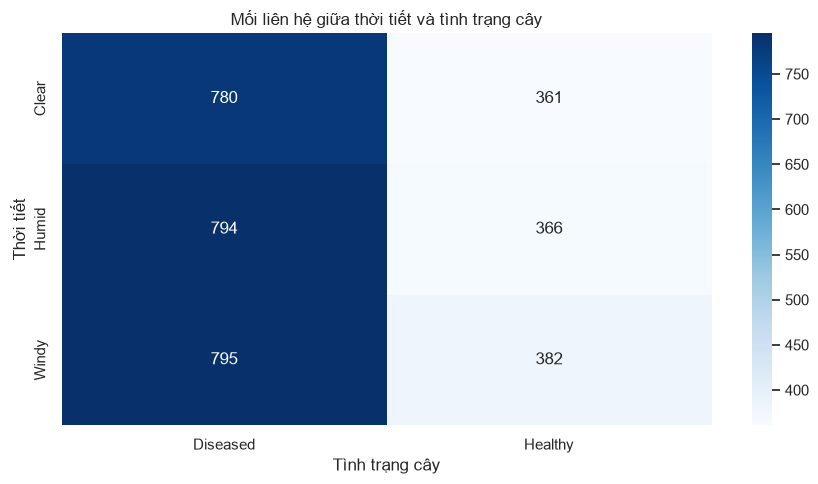

In [14]:
weather_health = pd.crosstab(
    df_metadata["Environmental_Conditions.Weather"],
    df_metadata["Plant_Health_Status"]
)
display(weather_health)

plt.figure(figsize=(9, 5))

sns.heatmap(
    weather_health,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Mối liên hệ giữa thời tiết và tình trạng cây")
plt.xlabel("Tình trạng cây")
plt.ylabel("Thời tiết")

plt.tight_layout()
plt.show()

7.5.2 ánh sáng và tình trạng cây (Lightning x Plant_Health_Status)

Plant_Health_Status,Diseased,Healthy
Environmental_Conditions.Weather,,
Clear,780,361
Humid,794,366
Windy,795,382


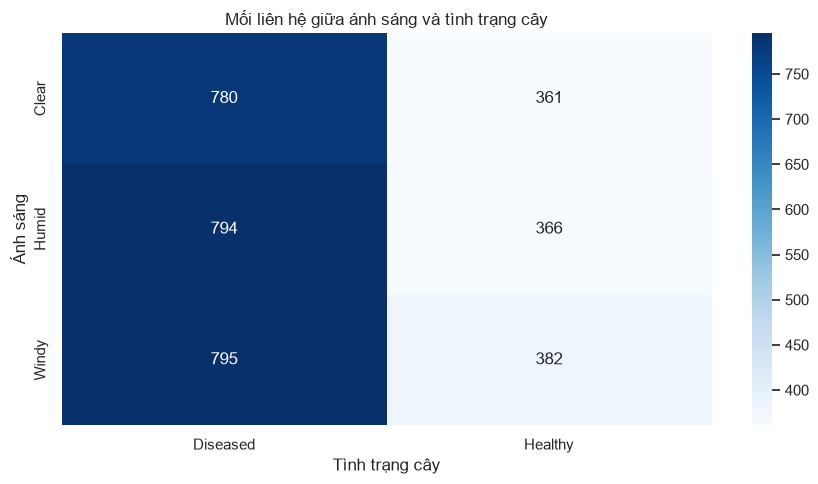

In [15]:
lighting_health = pd.crosstab(
    df_metadata["Environmental_Conditions.Lighting"],
    df_metadata["Plant_Health_Status"]
)
display(weather_health)

plt.figure(figsize=(9, 5))

sns.heatmap(
    weather_health,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Mối liên hệ giữa ánh sáng và tình trạng cây")
plt.xlabel("Tình trạng cây")
plt.ylabel("Ánh sáng")

plt.tight_layout()
plt.show()

7.5.3 thời điểm và tình trạng cây (Time_of_Capture x Plant_Health_Status)

Plant_Health_Status,Diseased,Healthy
Environmental_Conditions.Weather,,
Clear,780,361
Humid,794,366
Windy,795,382


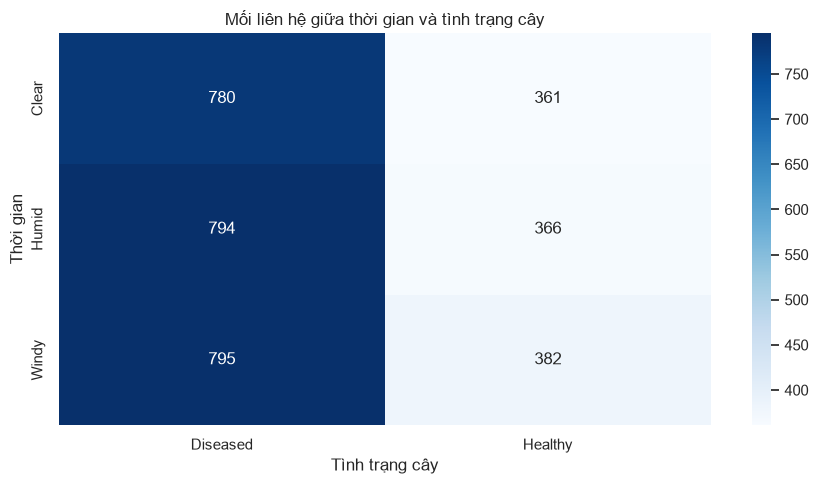

In [16]:
time_health = pd.crosstab(
    df_metadata["Environmental_Conditions.Time_of_Capture"],
    df_metadata["Plant_Health_Status"]
)
display(weather_health)

plt.figure(figsize=(9, 5))

sns.heatmap(
    weather_health,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Mối liên hệ giữa thời gian và tình trạng cây")
plt.xlabel("Tình trạng cây")
plt.ylabel("Thời gian")

plt.tight_layout()
plt.show()

7.5.4 phân bố các loại bệnh ở các vườn (Vineyard x Disease_Type)

Disease_Type,Black Rot,Esca,Healthy,Leaf Blight
Location.Vineyard,,,,
Vineyard_1,14 (12.84%),34 (31.19%),38 (34.86%),23 (21.1%)
Vineyard_10,34 (27.2%),37 (29.6%),34 (27.2%),20 (16.0%)
Vineyard_11,29 (21.8%),41 (30.83%),40 (30.08%),23 (17.29%)
Vineyard_12,33 (24.63%),33 (24.63%),41 (30.6%),27 (20.15%)
Vineyard_13,26 (22.22%),29 (24.79%),41 (35.04%),21 (17.95%)
Vineyard_14,30 (25.64%),30 (25.64%),35 (29.91%),22 (18.8%)
Vineyard_15,21 (16.8%),30 (24.0%),35 (28.0%),39 (31.2%)
Vineyard_16,18 (16.51%),27 (24.77%),44 (40.37%),20 (18.35%)
Vineyard_17,32 (26.02%),31 (25.2%),35 (28.46%),25 (20.33%)


<Figure size 1400x700 with 0 Axes>

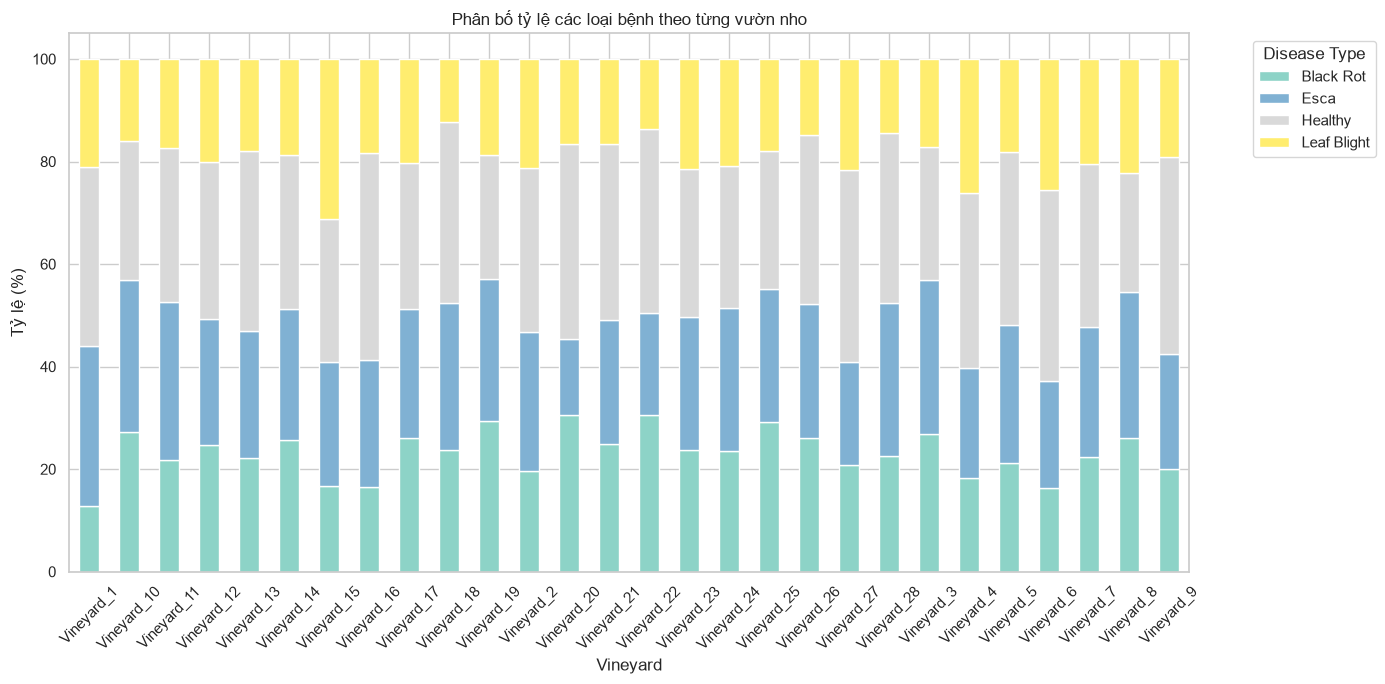

In [17]:
# Bảng số lượng
df_vineyard_count = pd.crosstab(
    df_metadata["Location.Vineyard"],
    df_metadata["Disease_Type"]
)

# Bảng tỷ lệ (%)
df_vineyard_percent = pd.crosstab(
    df_metadata["Location.Vineyard"],
    df_metadata["Disease_Type"],
    normalize="index"
) * 100

# Gộp số lượng và tỷ lệ vào cùng một bảng
df_vineyard_summary = df_vineyard_count.astype(str) + " (" + df_vineyard_percent.round(2).astype(str) + "%)"

display(df_vineyard_summary)

# Trực quan hóa tỷ lệ %
plt.figure(figsize=(14, 7))

df_vineyard_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    colormap="Set3"
)

plt.title("Phân bố tỷ lệ các loại bệnh theo từng vườn nho")
plt.xlabel("Vineyard")
plt.ylabel("Tỷ lệ (%)")
plt.xticks(rotation=45)
plt.legend(title="Disease Type", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

7.5.5 phân bố theo điều kiện thời tiết (Weather x Disease_Type)

Count                           \
Disease_Type                     Black Rot Esca Healthy Leaf Blight   
Environmental_Conditions.Weather                                      
Clear                                  285  288     361         207   
Humid                                  257  288     366         249   
Windy                                  267  312     382         216   

                                 Percentage (%)                             
Disease_Type                          Black Rot   Esca Healthy Leaf Blight  
Environmental_Conditions.Weather                                            
Clear                                     24.98  25.24   31.64       18.14  
Humid                                     22.16  24.83   31.55       21.47  
Windy                                     22.68  26.51   32.46       18.35

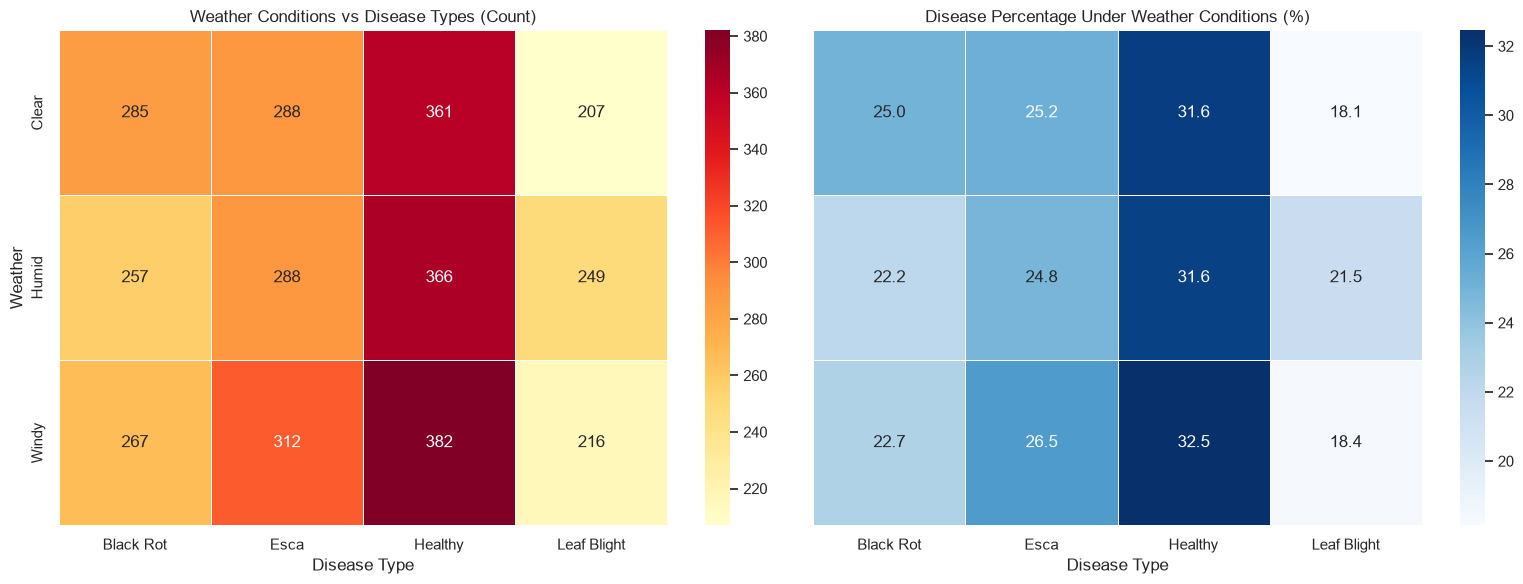

In [18]:
def analyze_weather_disease(df, weather_col="Environmental_Conditions.Weather", disease_col="Disease_Type"):
    # 1. Tính toán số lượng và tỷ lệ phần trăm
    df_count = pd.crosstab(df[weather_col], df[disease_col])
    df_percent = df_count.div(df_count.sum(axis=1), axis=0) * 100

    # Gộp 2 bảng thành 1 bảng tổng hợp để hiển thị gọn gàng
    df_summary = pd.concat([df_count, df_percent.round(2)], axis=1, keys=["Count", "Percentage (%)"])
    display(df_summary)

    # 2. Vẽ 2 biểu đồ cạnh nhau (1 hàng, 2 cột)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

    # Biểu đồ 1: Số lượng
    sns.heatmap(df_count, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5, ax=axes[0])
    axes[0].set_title("Weather Conditions vs Disease Types (Count)")
    axes[0].set_xlabel("Disease Type")
    axes[0].set_ylabel("Weather")

    # Biểu đồ 2: Phần trăm
    sns.heatmap(df_percent, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5, ax=axes[1])
    axes[1].set_title("Disease Percentage Under Weather Conditions (%)")
    axes[1].set_xlabel("Disease Type")
    axes[1].set_ylabel("") # Ẩn nhãn trục Y bên phải vì đã dùng chung với bên trái

    plt.tight_layout()
    plt.show()

# Gọi hàm chạy
analyze_weather_disease(df_metadata)

7.5.6 GPS x Disease_Type

Số lượng mẫu có GPS hợp lệ: 3478

--- Phân bố theo tọa độ (Top 10) ---


,Disease_Type,Black Rot,Esca,Healthy,Leaf Blight
Location.GPS.Latitude,Location.GPS.Longitude,,,,
18.731029,73.977206,28,37,41,18
18.734004,74.054693,34,37,34,20
18.735187,74.005753,18,27,44,20
18.742834,74.051588,26,29,41,21
18.744878,74.018640,29,35,43,15
18.750256,73.990160,32,31,35,25
18.753966,74.028567,39,35,36,24
18.759723,74.052451,33,33,41,27
18.770889,74.024265,23,27,43,33



--- Thống kê theo từng vườn nho ---


,Location.Vineyard,Disease_Type,Sample_Count,Average_Latitude,Average_Longitude
0,Vineyard_1,Black Rot,14,18.810208,73.989924
1,Vineyard_1,Esca,34,18.810208,73.989924
2,Vineyard_1,Healthy,38,18.810208,73.989924
3,Vineyard_1,Leaf Blight,23,18.810208,73.989924
4,Vineyard_10,Black Rot,34,18.734004,74.054693
...,...,...,...,...,...
107,Vineyard_8,Leaf Blight,29,18.790580,74.002429
108,Vineyard_9,Black Rot,25,18.798335,74.046139
109,Vineyard_9,Esca,28,18.798335,74.046139
110,Vineyard_9,Healthy,48,18.798335,74.046139


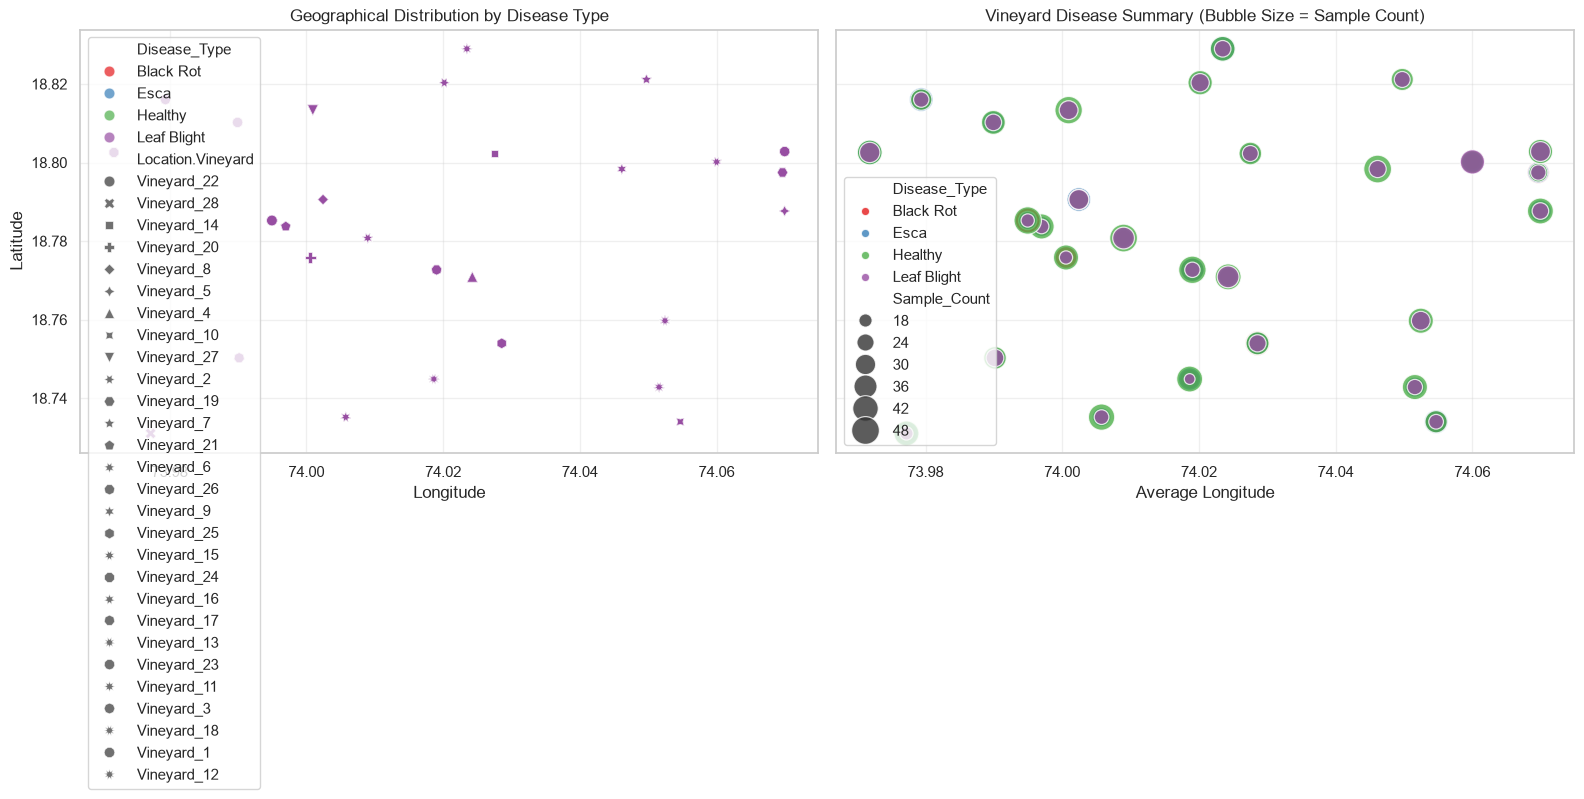

In [19]:
def analyze_gps_disease(df):
    # 1. Trích xuất, ép kiểu số và lọc bỏ giá trị thiếu gọn trong 1 bước
    cols = ["Location.GPS.Latitude", "Location.GPS.Longitude", "Disease_Type", "Location.Vineyard"]
    df_gps = df[cols].copy()
    
    for col in ["Location.GPS.Latitude", "Location.GPS.Longitude"]:
        df_gps[col] = pd.to_numeric(df_gps[col], errors="coerce")
        
    df_gps = df_gps.dropna(subset=["Location.GPS.Latitude", "Location.GPS.Longitude", "Disease_Type"])
    print(f"Số lượng mẫu có GPS hợp lệ: {len(df_gps)}")

    # 2. Thống kê theo tọa độ & theo từng vườn
    df_gps_dist = pd.crosstab([df_gps["Location.GPS.Latitude"], df_gps["Location.GPS.Longitude"]], df_gps["Disease_Type"])
    
    df_vineyard_gps = df_gps.groupby(["Location.Vineyard", "Disease_Type"]).agg(
        Sample_Count=("Disease_Type", "count"),
        Average_Latitude=("Location.GPS.Latitude", "mean"),
        Average_Longitude=("Location.GPS.Longitude", "mean")
    ).reset_index()

    print("\n--- Phân bố theo tọa độ (Top 10) ---")
    display(df_gps_dist.head(10))
    print("\n--- Thống kê theo từng vườn nho ---")
    display(df_vineyard_gps)

    # 3. Trực quan hóa 2 biểu đồ cạnh nhau
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

    # Biểu đồ 1: Phân bố chi tiết từng mẫu theo Loại bệnh
    sns.scatterplot(
        data=df_gps, x="Location.GPS.Longitude", y="Location.GPS.Latitude",
        hue="Disease_Type", style="Location.Vineyard", palette="Set1", s=60, alpha=0.7, ax=axes[0]
    )
    axes[0].set_title("Geographical Distribution by Disease Type")
    axes[0].set_xlabel("Longitude")
    axes[0].set_ylabel("Latitude")
    axes[0].grid(alpha=0.3)

    # Biểu đồ 2: Tổng hợp theo Vườn (kích thước điểm = số lượng mẫu)
    sns.scatterplot(
        data=df_vineyard_gps, x="Average_Longitude", y="Average_Latitude",
        hue="Disease_Type", size="Sample_Count", sizes=(50, 400), palette="Set1", alpha=0.8, ax=axes[1]
    )
    axes[1].set_title("Vineyard Disease Summary (Bubble Size = Sample Count)")
    axes[1].set_xlabel("Average Longitude")
    axes[1].set_ylabel("")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
    
    return df_gps, df_vineyard_gps

# Gọi hàm
df_gps_clean, df_vineyard_summary = analyze_gps_disease(df_metadata)

**8.KIỂM TRA CHẤT LƯỢNG DATA**

**9.TỔNG KẾT**